In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, KFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

In [ ]:
df = pd.read_csv("/content/Unemployment in India.csv")

In [ ]:
df.head()

,Region\t Date\t Frequency\t Estimated Unemployment Rate (%)\t Estimated Employed\t Estimated Labour Participation Rate (%)\tArea
0,Andhra Pradesh\t 31-05-2019\t Monthly\t3.65\t1...
1,Andhra Pradesh\t 30-06-2019\t Monthly\t3.05\t1...
2,Andhra Pradesh\t 31-07-2019\t Monthly\t3.75\t1...
3,Andhra Pradesh\t 31-08-2019\t Monthly\t3.32\t1...
4,Andhra Pradesh\t 30-09-2019\t Monthly\t5.17\t1...


In [ ]:
df.tail()

,Region\t Date\t Frequency\t Estimated Unemployment Rate (%)\t Estimated Employed\t Estimated Labour Participation Rate (%)\tArea
735,West Bengal\t 29-02-2020\tMonthly\t7.55\t10871...
736,West Bengal\t 31-03-2020\tMonthly\t6.67\t10806...
737,West Bengal\t 30-04-2020\tMonthly\t15.63\t9299...
738,West Bengal\t 31-05-2020\tMonthly\t15.22\t9240...
739,West Bengal\t 30-06-2020\tMonthly\t9.86\t90889...


In [ ]:
df.shape

(740, 1)

In [ ]:
# Option A: Google Colab upload
from google.colab import files
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

if file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_name)
else:
    # sep=None + python engine lets pandas sniff the delimiter (comma, semicolon, tab)
    df = pd.read_csv(file_name, sep=None, engine="python", encoding="utf-8-sig")

print(df.shape)
print(df.columns.tolist())
df.head()

Saving Unemployment in India.csv to Unemployment in India (1).csv
(754, 7)
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


**Clean the data**

In [ ]:
df.columns = df.columns.str.strip()

assert df.shape[1] == 7, f"Expected 7 columns, got {df.shape[1]}: {df.columns.tolist()}"

df.columns = ["Region", "Date", "Frequency", "Unemployment_Rate",
              "Employed", "Labour_Participation_Rate", "Area"]

for col in ["Region", "Frequency", "Area"]:
    df[col] = df[col].astype(str).str.strip()

df["Date"] = pd.to_datetime(df["Date"].astype(str).str.strip(), dayfirst=True, errors="coerce")

df = df.dropna(how="all").drop_duplicates()
df = df.dropna(subset=["Date", "Unemployment_Rate"])

print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nFrequency values:\n", df["Frequency"].value_counts())

<class 'pandas.core.frame.DataFrame'>
Index: 740 entries, 0 to 753
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Region                     740 non-null    object        
 1   Date                       740 non-null    datetime64[ns]
 2   Frequency                  740 non-null    object        
 3   Unemployment_Rate          740 non-null    float64       
 4   Employed                   740 non-null    float64       
 5   Labour_Participation_Rate  740 non-null    float64       
 6   Area                       740 non-null    object        
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 46.2+ KB
None

Missing values:
 Region                       0
Date                         0
Frequency                    0
Unemployment_Rate            0
Employed                     0
Labour_Participation_Rate    0
Area                         0
dtype: int64

Frequenc

**Exploratory data analysis**

                                Date  Unemployment_Rate      Employed  \
count                            740         740.000000  7.400000e+02   
mean   2019-12-12 18:36:58.378378496          11.787946  7.204460e+06   
min              2019-05-31 00:00:00           0.000000  4.942000e+04   
25%              2019-08-31 00:00:00           4.657500  1.190404e+06   
50%              2019-11-30 00:00:00           8.350000  4.744178e+06   
75%              2020-03-31 00:00:00          15.887500  1.127549e+07   
max              2020-06-30 00:00:00          76.740000  4.577751e+07   
std                              NaN          10.721298  8.087988e+06   

       Labour_Participation_Rate  
count                 740.000000  
mean                   42.630122  
min                    13.330000  
25%                    38.062500  
50%                    41.160000  
75%                    45.505000  
max                    72.570000  
std                     8.111094  


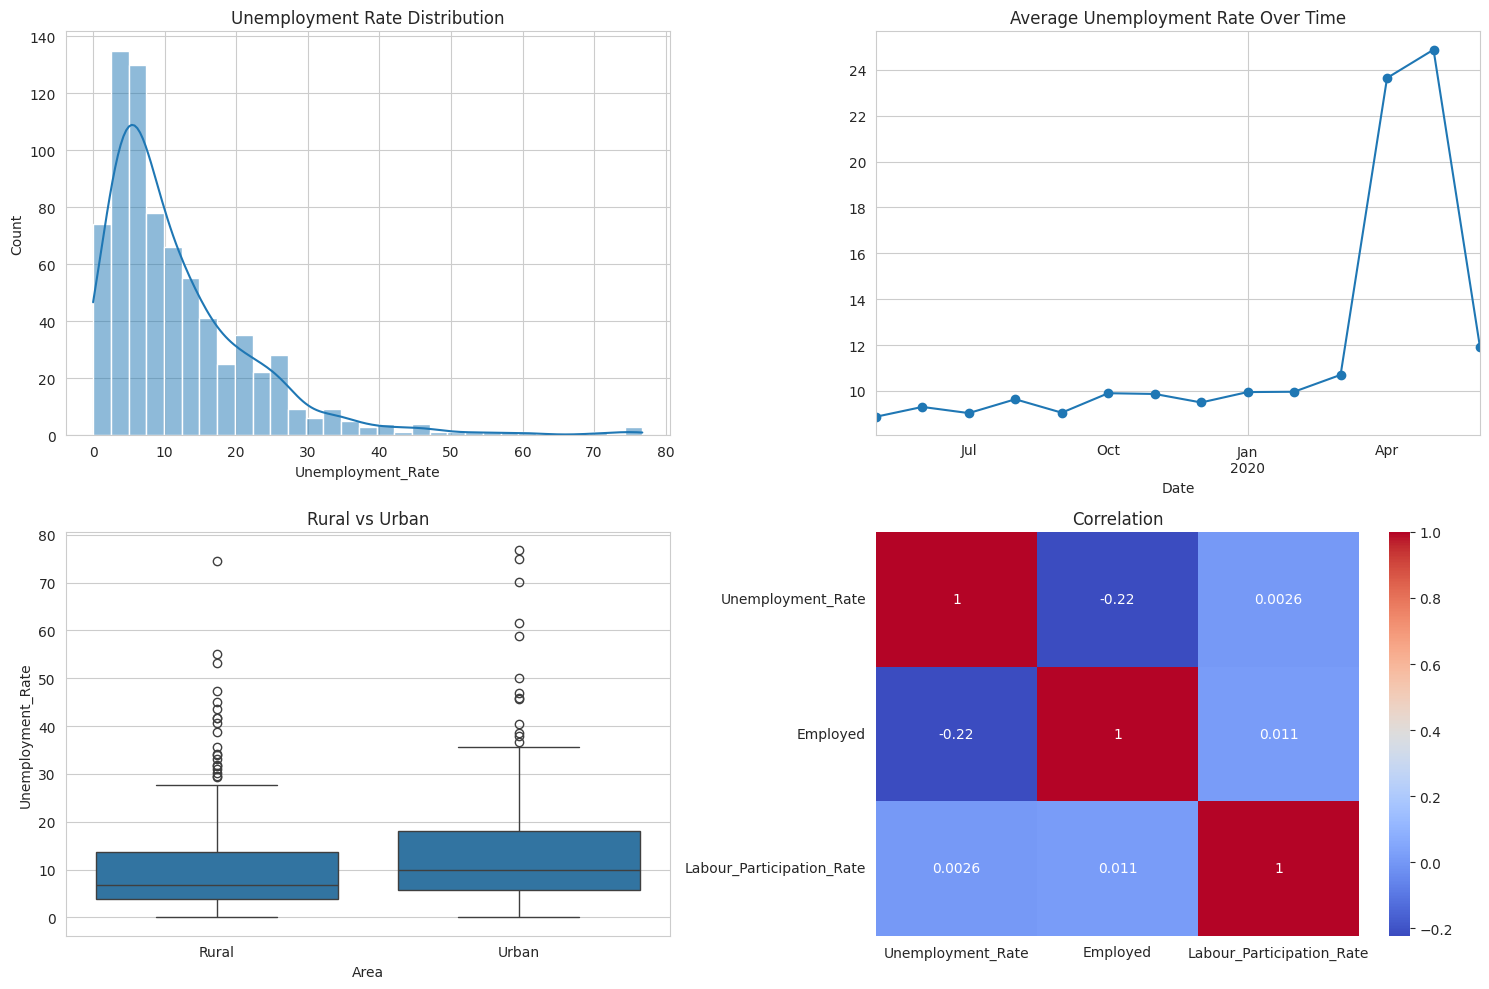

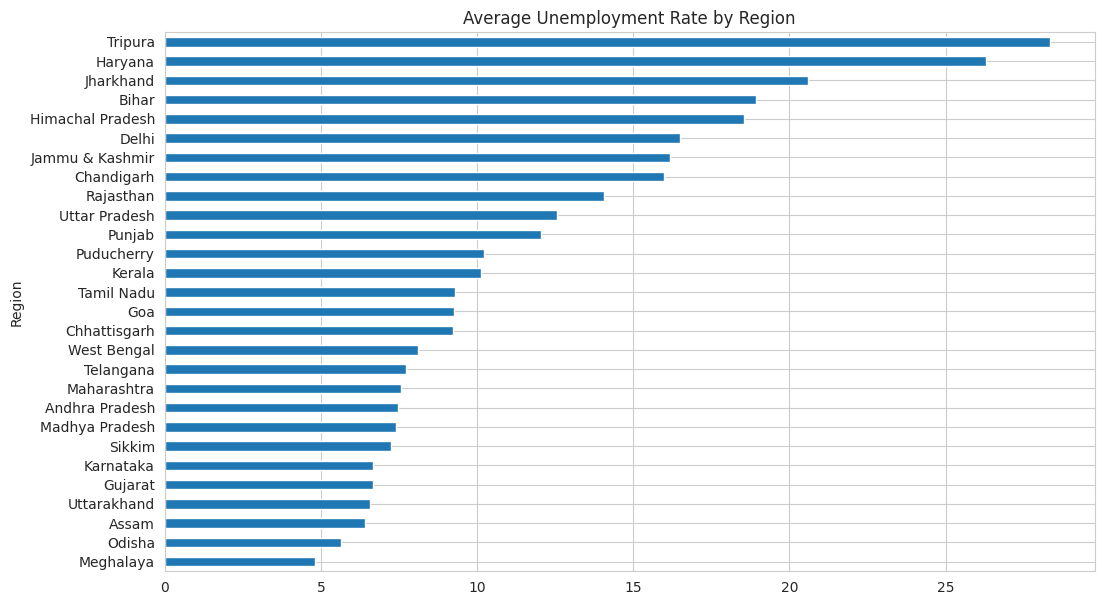

<Figure size 640x480 with 0 Axes>

In [ ]:
print(df.describe())

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Distribution of target
sns.histplot(df["Unemployment_Rate"], kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Unemployment Rate Distribution")

# Trend over time
df.groupby("Date")["Unemployment_Rate"].mean().plot(ax=axes[0, 1], marker="o")
axes[0, 1].set_title("Average Unemployment Rate Over Time")

# Rural vs Urban
sns.boxplot(data=df, x="Area", y="Unemployment_Rate", ax=axes[1, 0])
axes[1, 0].set_title("Rural vs Urban")

# Correlation
sns.heatmap(df[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]].corr(),
            annot=True, cmap="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("Correlation")

plt.tight_layout()
plt.show()

# Top regions by average unemployment
plt.figure(figsize=(12, 7))
df.groupby("Region")["Unemployment_Rate"].mean().sort_values().plot(kind="barh")
plt.title("Average Unemployment Rate by Region")
plt.show()
plt.savefig("eda.png")

**Feature engineering**

In [ ]:
data = df.copy()

data["Year"] = data["Date"].dt.year
data["Month"] = data["Date"].dt.month

# Flag the COVID lockdown period (strong structural shift)
data["Covid_Period"] = ((data["Date"] >= "2020-03-01")).astype(int)

# Employed has a huge scale, so use log
data["Log_Employed"] = np.log1p(data["Employed"])

# Frequency is nearly constant, so drop it. Keep Date only for splitting.
features_num = ["Log_Employed", "Labour_Participation_Rate", "Month", "Year", "Covid_Period"]
features_cat = ["Region", "Area"]
target = "Unemployment_Rate"

X = data[features_num + features_cat]
y = data[target]
print(X.shape, y.shape)
X.head()

(740, 7) (740,)


,Log_Employed,Labour_Participation_Rate,Month,Year,Covid_Period,Region,Area
0,16.300346,43.24,5,2019,0,Andhra Pradesh,Rural
1,16.279864,42.05,6,2019,0,Andhra Pradesh,Rural
2,16.307617,43.50,7,2019,0,Andhra Pradesh,Rural
3,16.323946,43.97,8,2019,0,Andhra Pradesh,Rural
4,16.321588,44.68,9,2019,0,Andhra Pradesh,Rural


**Train/test split**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (592, 7) Test: (148, 7)


**Preprocessing pipeline**

In [ ]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), features_num),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), features_cat),
])

**Compare models with cross-validation**

In [ ]:
models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    r2 = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2")
    rmse = -cross_val_score(pipe, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
    results.append({"Model": name, "CV_R2": r2.mean(), "CV_RMSE": rmse.mean()})

results_df = pd.DataFrame(results).sort_values("CV_RMSE")
results_df

,Model,CV_R2,CV_RMSE
3,GradientBoosting,0.596073,6.528242
2,RandomForest,0.520419,7.061651
1,Ridge,0.426920,7.760026
0,LinearRegression,0.424775,7.769446
4,HistGradientBoosting,0.248997,8.935215


**Hyperparameter tuning (Random Forest)**

In [ ]:
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestRegressor(random_state=42, n_jobs=-1)),
])

param_dist = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", 1.0],
}

search = RandomizedSearchCV(
    rf_pipe, param_dist, n_iter=25, cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42, n_jobs=-1, verbose=1,
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV RMSE:", -search.best_score_)
best_model = search.best_estimator_

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best params: {'model__n_estimators': 500, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': None}
Best CV RMSE: 6.70846180992429


**Evaluate on the test set**

MAE : 3.806
RMSE: 6.637
R²  : 0.696


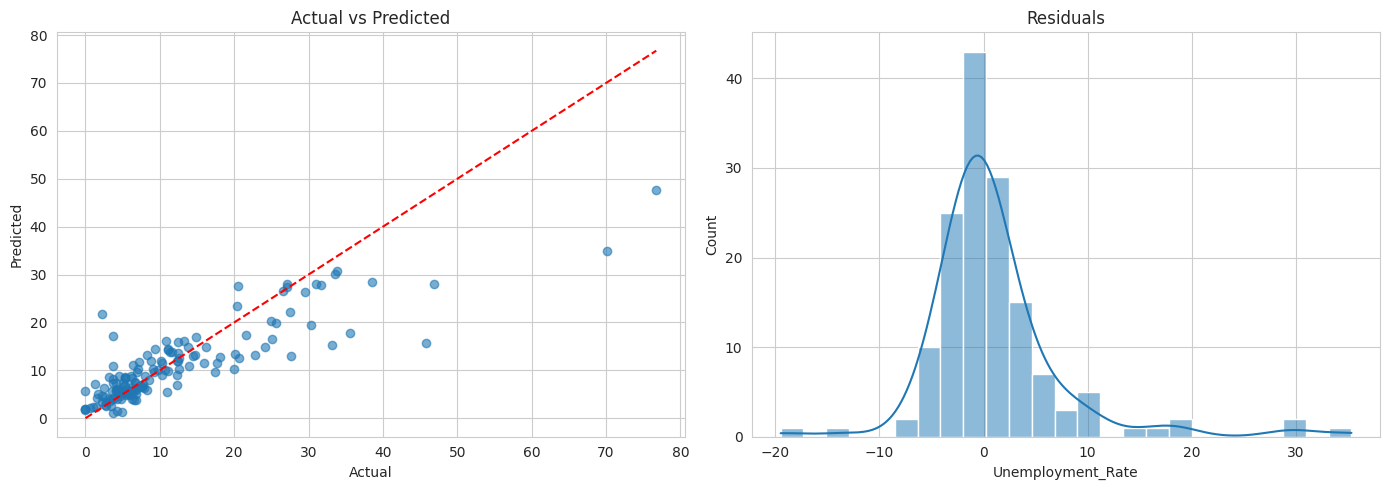

<Figure size 640x480 with 0 Axes>

In [ ]:
y_pred = best_model.predict(X_test)

print(f"MAE : {mean_absolute_error(y_test, y_pred):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.3f}")
print(f"R²  : {r2_score(y_test, y_pred):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred, alpha=0.6)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
axes[0].set_xlabel("Actual"); axes[0].set_ylabel("Predicted")
axes[0].set_title("Actual vs Predicted")

sns.histplot(y_test - y_pred, kde=True, ax=axes[1])
axes[1].set_title("Residuals")

plt.tight_layout()
plt.show()
plt.savefig("results.png")

**Feature importance**

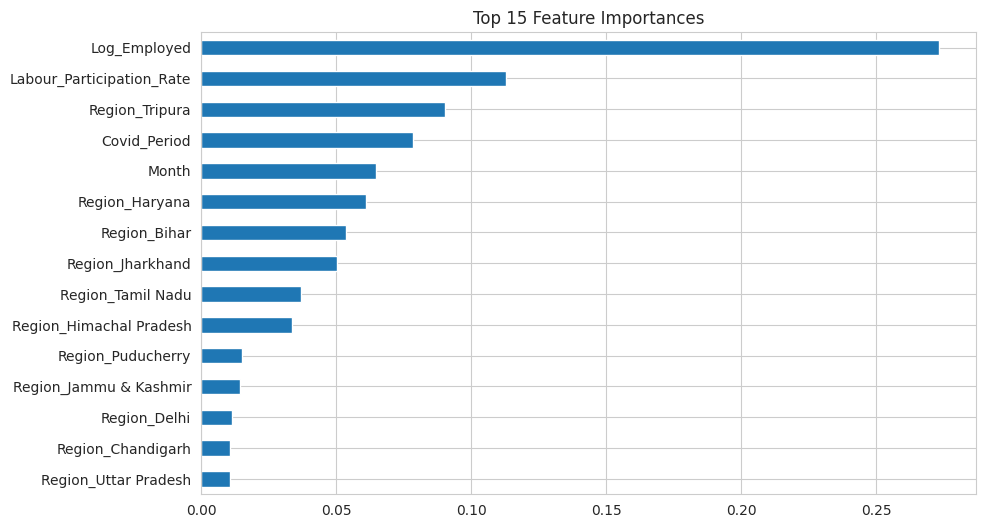

In [ ]:
prep = best_model.named_steps["prep"]
rf = best_model.named_steps["model"]

cat_names = prep.named_transformers_["cat"].get_feature_names_out(features_cat)
all_names = features_num + list(cat_names)

imp = pd.Series(rf.feature_importances_, index=all_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
imp[::-1].plot(kind="barh")
plt.title("Top 15 Feature Importances")
plt.show()

**Time-based validation (more realistic check)**

In [ ]:
cutoff = pd.Timestamp("2020-02-29")

train_mask = data["Date"] <= cutoff
X_tr, y_tr = X[train_mask], y[train_mask]
X_te, y_te = X[~train_mask], y[~train_mask]

# Covid_Period is always 0 in training here, so drop it for this test
num_t = [c for c in features_num if c != "Covid_Period"]
prep_t = ColumnTransformer([
    ("num", StandardScaler(), num_t),
    ("cat", OneHotEncoder(handle_unknown="ignore"), features_cat),
])
time_pipe = Pipeline([("prep", prep_t),
                      ("model", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))])
time_pipe.fit(X_tr[num_t + features_cat], y_tr)
pred_t = time_pipe.predict(X_te[num_t + features_cat])

print(f"Time-split MAE: {mean_absolute_error(y_te, pred_t):.3f}")
print(f"Time-split R² : {r2_score(y_te, pred_t):.3f}")

Time-split MAE: 10.213
Time-split R² : -0.217


**Save the model and predict on new data**

In [ ]:
joblib.dump(best_model, "unemployment_model.pkl")

# Load and predict
loaded = joblib.load("unemployment_model.pkl")

new_data = pd.DataFrame([{
    "Log_Employed": np.log1p(12_000_000),
    "Labour_Participation_Rate": 43.0,
    "Month": 7,
    "Year": 2020,
    "Covid_Period": 1,
    "Region": "Andhra Pradesh",
    "Area": "Rural",
}])

print("Predicted unemployment rate: %.2f%%" % loaded.predict(new_data)[0])

Predicted unemployment rate: 6.53%
